# Librerias

In [1]:
import sys
import os
import datetime
import time
# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, PReLU, Dropout, Input,Rescaling, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import MobileNetV2
from keras.metrics import Precision, Recall, AUC
import keras


from src.Modelo_CNN import CNN_Model_Clasification

I0000 00:00:1794266770.017124   11144 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Instancia para modelado

In [3]:

img_classify = CNN_Model_Clasification(8,300,300,3)
img_classify.buffer_size = 200
img_classify.lab_mode = "int"
img_classify.categories = ['aegypti', 'albopictus', 'anopheles', 'culex']

# Carga de subsets

In [4]:
img_classify.train_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/train/'

img_classify.val_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/val/'

img_classify.test_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/test/'


img_classify.classify_img_by_folder()



Found 12000 files belonging to 4 classes.


I0000 00:00:1794083543.523941   57113 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Found 4000 files belonging to 4 classes.
Found 12636 files belonging to 4 classes.
Categorias de instancia: ['aegypti', 'albopictus', 'anopheles', 'culex']
Train data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Validation data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Test data: ['aegypti', 'albopictus', 'anopheles', 'culex']


In [5]:

for lote_imagenes, lote_etiquetas in img_classify.train_data.take(1):
    
    # Convertimos los tensores a arrays de NumPy para inspeccionar sus dimensiones
    print("Forma del lote de imágenes:", lote_imagenes.numpy().shape) 
    # Resultado ej: (32, 256, 256, 3) -> (Batch, Alto, Ancho, Canales)
    
    print("Forma del lote de etiquetas:", lote_etiquetas.numpy().shape)
    # Resultado ej: (32,) -> Un número entero por cada imagen del lote
    
    # Ver los valores numéricos de las primeras 5 etiquetas del lote
    print("Primeras 5 etiquetas numéricas del lote:", lote_etiquetas.numpy()[:5])


Forma del lote de imágenes: (8, 300, 300, 3)
Forma del lote de etiquetas: (8,)
Primeras 5 etiquetas numéricas del lote: [3 2 2 3 0]


Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


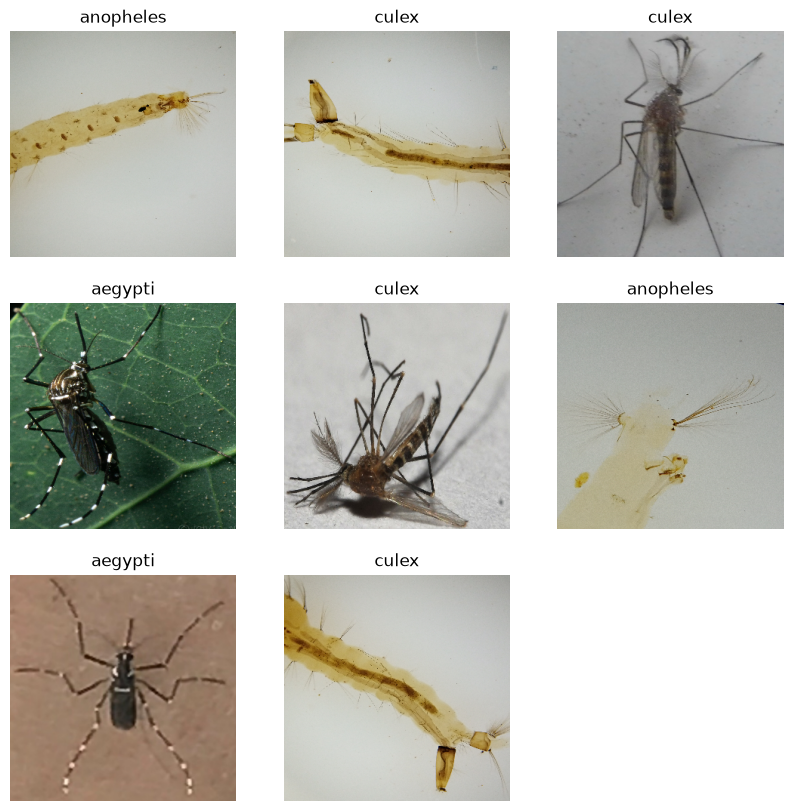

In [6]:

img_classify.show_sample_image_x_label('train')


Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


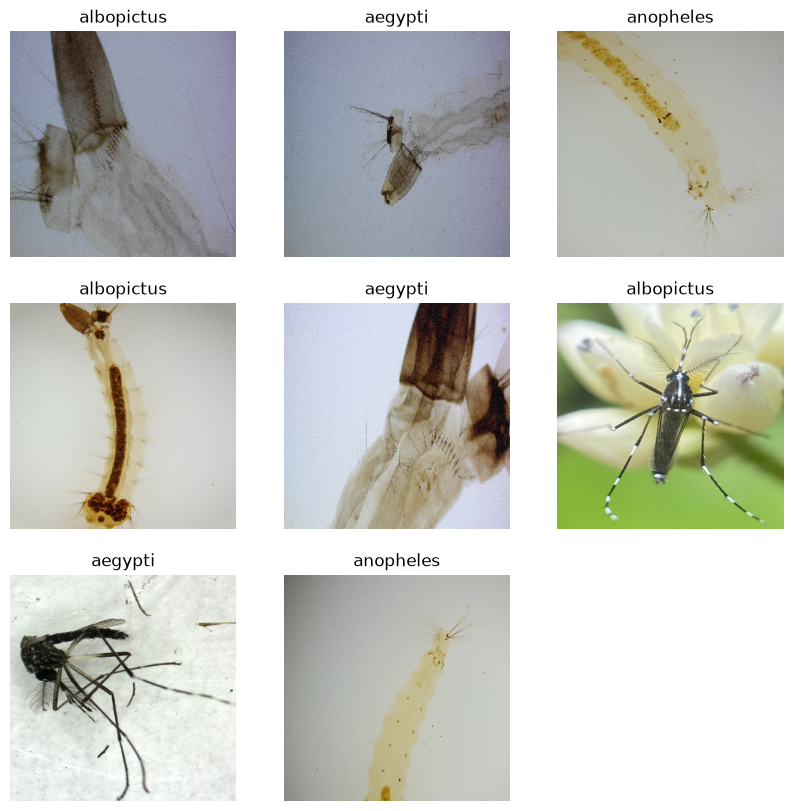

In [7]:
img_classify.show_sample_image_x_label('val')

Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


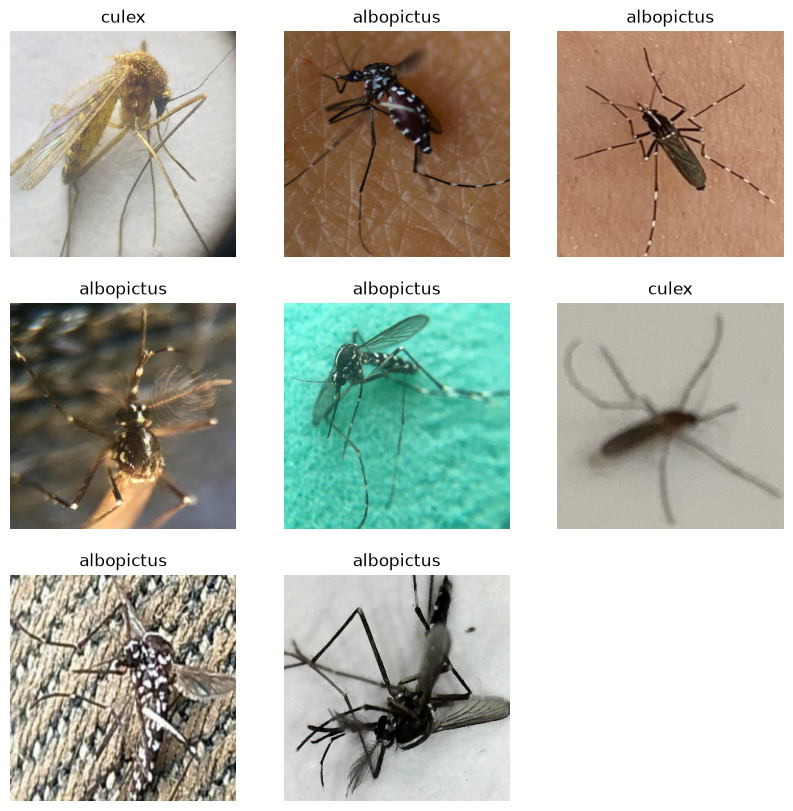

In [8]:
img_classify.show_sample_image_x_label('test')

# Configuracion de flujo y entrenamineto

In [9]:

img_classify.preparar_experimento(                                 
).model_flow_settings(
    capas_conv = 4,
    n_filtros = 32,
    n_filter_up_escale = 2,
    kernel_size = (5,5),
    pool_layer = 'max',
    pool_size = (2,2),
    transition = 'GAP',
    capas_densas = 3, 
    fun_act = 'mish',
    loss = 'sparse_categorical_crossentropy',
    optimizer = 'adam',
    n_output = len(img_classify.categories),
    dropout = 0,
    fun_out= 'softmax',
    leakyrelu_negative_slope = 0.5,
    n_dense_keep = 0.7,
    metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
).model.summary()


/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/.Vector_IA_wsl/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 300, 300, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 300, 300, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300, 300, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 300, 300, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 256)    │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 37, 37, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 179)            │        46,003 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 125)            │        22,50

 Total params: 1,159,817 (4.42 MB)

 Trainable params: 1,158,857 (4.42 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:

img_classify.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/CNN_Models/Img_classify/checkpoints/CNN_Vector_Clasification_8.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)

🚀 Iniciando el entrenamiento...

Epoch 1/600


/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/.Vector_IA_wsl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794005087.536379   34178 cuda_dnn.cc:461] Loaded cuDNN version 92700


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 326s 210ms/step - accuracy: 0.3442 - loss: 1.3356 - val_accuracy: 0.3728 - val_loss: 1.2614
Epoch 2/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 249s 166ms/step - accuracy: 0.3824 - loss: 1.2848 - val_accuracy: 0.3853 - val_loss: 1.2512
Epoch 3/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 267s 178ms/step - accuracy: 0.4283 - loss: 1.2186 - val_accuracy: 0.4873 - val_loss: 1.1094
Epoch 4/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 240s 159ms/step - accuracy: 0.4790 - loss: 1.1274 - val_accuracy: 0.3405 - val_loss: 1.4999
Epoch 5/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 242s 161ms/step - accuracy: 0.5218 - loss: 1.0545 - val_accuracy: 0.5807 - val_loss: 1.0471
Epoch 6/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 238s 159ms/step - accuracy: 0.5422 - loss: 1.0012 - val_accuracy: 0.5375 - val_loss: 1.1135
Epoch 7/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 238s 159ms/step - accuracy: 0.5589 - loss: 0.9558 - val_accuracy: 0.5253 - val_loss: 1.3691
Epoch 8/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 237s 158ms/step - accura

In [11]:
losses = pd.DataFrame(img_classify.model.history.history)


<Axes: >

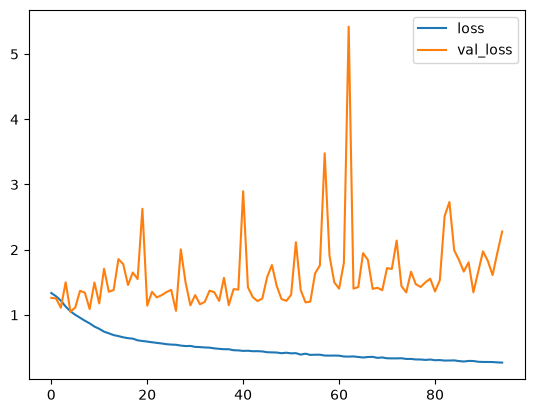

In [12]:

losses[['loss','val_loss']].plot()

<Axes: >

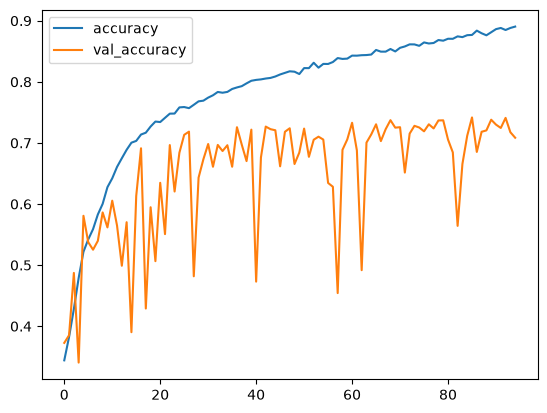

In [13]:
losses[['accuracy', 'val_accuracy']].plot()

# Evaluacion

In [5]:
img_classify.model = tf.keras.models.load_model("../models/CNN_Models/Img_classify/CNN_Vector_Clasification_9.keras")

In [6]:
img_classify.model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 300, 300, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 300, 300, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300, 300, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 300, 300, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 256)    │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 37, 37, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 179)            │        46,003 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 125)            │        22,50

 Total params: 3,477,533 (13.27 MB)

 Trainable params: 1,158,857 (4.42 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 2,317,716 (8.84 MB)

In [7]:
img_classify.img_prediction(
    '../data/raw/Imagenes/test/aegypti/6181896.png'
)

img_classify.predictions

I0000 00:00:1794083599.521781   57293 cuda_dnn.cc:461] Loaded cuDNN version 92700


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 954ms/step


'anopheles'

Conjunto: val | Ejemplos: 4000
accuracy           0.5808
precision_macro    0.5980
recall_macro       0.5808
f1_macro           0.5718
f1_ponderado       0.5718
dtype: float64

Reporte por clase:
            precision  recall  f1-score  support
Clase                                           
aegypti        0.5653   0.701    0.6259     1000
albopictus     0.6947   0.421    0.5243     1000
anopheles      0.5387   0.758    0.6298     1000
culex          0.5930   0.443    0.5072     1000


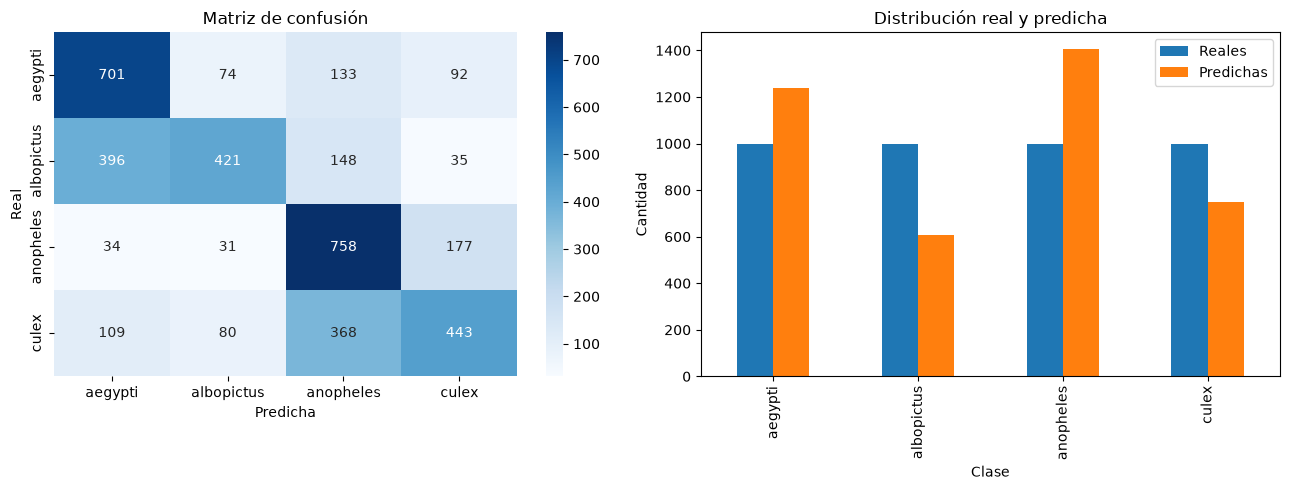

,Clase_real,Clase_predicha,Nombre_real,Nombre_predicho,Probabilidad_clase_predicha,Acierto
0,1,3,albopictus,culex,0.504081,False
1,0,3,aegypti,culex,0.447297,False
4,1,0,albopictus,aegypti,0.588995,False
10,3,2,culex,anopheles,0.321889,False
15,3,2,culex,anopheles,0.388443,False
...,...,...,...,...,...,...
3979,3,2,culex,anopheles,0.460467,False
3981,0,1,aegypti,albopictus,0.310064,False
3986,3,2,culex,anopheles,0.363066,False
3987,2,3,anopheles,culex,0.463431,False


In [8]:
resultado = img_classify.evaluar(
    conjunto="val",
    tipo="multiclase",
    codificacion="indices"
)

resultado["reporte_por_clase"]
resultado["predicciones"].query("Acierto == False")

In [ ]:
# Una vez terminado model.fit(...)
#nombre_archivo = "../models/CNN_Models/Img_classify/CNN_Vector_Clasification_9.keras"

# Guardar el modelo completo
#img_classify.model.save(nombre_archivo)
#print(f"Modelo guardado exitosamente en: {nombre_archivo}")


Modelo guardado exitosamente en: ../models/CNN_Models/Img_classify/CNN_Vector_Clasification_9.keras


## Craecion de MovilNet

In [2]:
model_mnV2 = CNN_Model_Clasification(8,224,224,3)
model_mnV2.buffer_size = 200
model_mnV2.lab_mode = "int"
model_mnV2.categories = ['aegypti', 'albopictus', 'anopheles', 'culex']

model_mnV2.train_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/train/'

model_mnV2.val_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/val/'

model_mnV2.test_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/test/'

model_mnV2.classify_img_by_folder()

Found 12000 files belonging to 4 classes.


I0000 00:00:1794266826.182503   11144 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Found 4000 files belonging to 4 classes.
Found 12636 files belonging to 4 classes.
Categorias de instancia: ['aegypti', 'albopictus', 'anopheles', 'culex']
Train data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Validation data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Test data: ['aegypti', 'albopictus', 'anopheles', 'culex']


In [3]:
base_model = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.15
    ),

    tf.keras.layers.RandomZoom(
        0.15
    )

])

base_model.trainable = False

model_mobilenet = Sequential([

    Input(
        shape=(224,224,3)
    ),

    Rescaling(1./255),

    data_augmentation,

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(
        0.5
    ),

    Dense(
        4,
        activation="softmax",
        dtype="float32"
    )

])

model_mobilenet.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

model_mnV2.model = model_mobilenet

In [ ]:
model_mnV2.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=10,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/CNN_Models/Img_classify/checkpoints/CNN_Vector_Clasification_8.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)

🚀 Iniciando el entrenamiento...

Epoch 1/600


/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/.Vector_IA_wsl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794266847.477595   11383 cuda_dnn.cc:461] Loaded cuDNN version 92700


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 368s 239ms/step - accuracy: 0.6168 - loss: 0.8688 - val_accuracy: 0.6658 - val_loss: 0.9863
Epoch 2/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 151s 101ms/step - accuracy: 0.6913 - loss: 0.7032 - val_accuracy: 0.6790 - val_loss: 1.2179
Epoch 3/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 140s 93ms/step - accuracy: 0.7078 - loss: 0.6674 - val_accuracy: 0.6975 - val_loss: 1.2946
Epoch 4/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 135s 90ms/step - accuracy: 0.7118 - loss: 0.6529 - val_accuracy: 0.6848 - val_loss: 1.1399
Epoch 5/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 133s 89ms/step - accuracy: 0.7222 - loss: 0.6330 - val_accuracy: 0.6895 - val_loss: 1.1290
Epoch 6/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 128s 85ms/step - accuracy: 0.7301 - loss: 0.6289 - val_accuracy: 0.6902 - val_loss: 1.4430
Epoch 7/600
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.7298 - loss: 0.6056


KeyboardInterrupt



In [1]:
resultado = model_mnV2.evaluar(
    conjunto="val",
    tipo="multiclase",
    codificacion="indices"
)

resultado["reporte_por_clase"]
resultado["predicciones"].query("Acierto == False")

NameError: name 'model_mnV2' is not defined